# 06 · Usuarios simulados: perfil, clóset e historial (fase 1, DeepFM)

Etapa 6 (revisión §12.3). Polyvore no trae usuarios, así que se simulan **300 usuarios** con clóset mixto (**70 % Polyvore / 30 % catálogo propio**) y **50 usuarios de transferencia** con clóset 100 % propio (§12.12, prueba de cambio de dominio). Cada usuario ve **50 outfits** armados con su clóset, en orden de fecha, y acepta o rechaza según su gusto simulado más un 5–10 % de ruido (`src/modelo_fly/usuarios.py`).

**Decisiones de diseño:**
- Las prendas Polyvore de los clósets salen **solo de valid y test** de la partición del paso 4b: la fase 2 nunca las ve al entrenar.
- El gusto combina las 7 reglas, el estilo favorito, el clima de su ciudad, el gusto por neutros y una **compatibilidad humana** aprendida de Polyvore (outfits reales vs. aleatorios de train). Así la etiqueta no sale solo de las reglas (riesgo de circularidad, §12.3).
- Se guardan los parámetros reales de cada usuario para medir después si el DeepFM recupera sus gustos.

**Salidas:** `data/processed/hito3/usuarios.csv`, `closets.csv`, `historial.csv` e `items_fase1.csv`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró data/raw. Abre el notebook dentro del repositorio.")
sys.path.insert(0, str(ROOT / "src"))

from modelo_fly.reglas import REGLAS
from modelo_fly.usuarios import ATRIBUTOS, Compatibilidad, armar_closet, generar_perfiles, simular_historial

PROC = ROOT / "data" / "processed" / "hito3"
RES = ROOT / "results" / "hito3"
SEMILLA = 2026

productos = pd.read_csv(PROC / "fase2_productos.csv", dtype=str, keep_default_na=False)
outfits = pd.read_csv(PROC / "fase2_outfits.csv", dtype={"tids": str, "particion": str, "tipo": str})
propio = pd.read_csv(PROC / "catalogo_propio.csv", dtype=str, keep_default_na=False)
propio = propio[propio["calidad"] != "excluido"]

productos["item_id"] = "pv_" + productos["tid"]
items = pd.concat([productos.assign(origen="polyvore")[["item_id", "origen", "particion", "name", *ATRIBUTOS]],
                   propio.assign(particion="", name=propio["texto"])[["item_id", "origen", "particion", "name", *ATRIBUTOS]]],
                  ignore_index=True)
atrib = items.set_index("item_id")[ATRIBUTOS].to_dict("index")
outfits["ids"] = outfits["tids"].str.split("|").map(lambda t: ["pv_" + x for x in t])
pool_polyvore = items[(items["origen"] == "polyvore") & items["particion"].isin(["valid", "test"])]
pool_propio = items[items["origen"] == "propio"]
print("Prendas disponibles para clósets: Polyvore (valid+test)", len(pool_polyvore), "| propias", len(pool_propio))
display(pd.crosstab(items["slot"], items["origen"]))

Prendas disponibles para clósets: Polyvore (valid+test) 21832 | propias 500


origen,polyvore,propio
slot,,
abajo,8290,185
accesorio,7257,0
arriba,9216,141
bolso,9514,0
calzado,11910,33
exterior,4870,66
joyeria,10492,0
vestido,3817,75


## 1. Compatibilidad humana (de Polyvore)

Para cada par de prendas de un outfit se miran tono, patrón, material y estilo (con su slot). El puntaje es el log-cociente entre lo seguido que aparece ese par en outfits **reales** y en negativos **aleatorios**, contado solo en **train**. Se valida en valid: si separa lo real de lo falso mejor que las reglas (AUC 0,539 en la etapa 4), aporta una señal humana que las reglas no tienen.

In [2]:
tr = outfits[outfits["particion"] == "train"]
compat = Compatibilidad(tr.loc[tr["tipo"] == "real", "ids"], tr.loc[tr["tipo"] == "aleatorio", "ids"], atrib)
va = outfits[outfits["particion"] == "valid"].copy()
va["compat"] = [compat.puntaje([atrib[i] for i in ids]) for ids in va["ids"]]
filas = []
for t in ["aleatorio", "dificil"]:
    d = va[va["tipo"].isin(["real", t])]
    filas.append({"negativo": t, "AUC_compatibilidad": round(roc_auc_score(d["real"], d["compat"]), 3),
                  "AUC_score_reglas": round(roc_auc_score(d["real"], d["score"]), 3)})
display(pd.DataFrame(filas).set_index("negativo"))
print("Pares de atributos en la tabla:", len(compat.tabla))
COMPAT_MEDIA, COMPAT_DESV = va["compat"].mean(), va["compat"].std()

,AUC_compatibilidad,AUC_score_reglas
negativo,,
aleatorio,0.702,0.535
dificil,0.562,0.518


Pares de atributos en la tabla: 9165


## 2. Perfiles y clósets

In [3]:
perfiles = pd.concat([generar_perfiles(300, SEMILLA, "mixto"),
                      generar_perfiles(50, SEMILLA + 1, "transferencia", inicio=300)], ignore_index=True)
rng = np.random.default_rng(SEMILLA)
closets = pd.concat([armar_closet(rng, u, pool_polyvore, pool_propio, 0.7 if u["grupo"] == "mixto" else 0.0)
                     for u in perfiles.to_dict("records")], ignore_index=True)
print("Usuarios:", perfiles["grupo"].value_counts().to_dict())
display(perfiles.groupby("arquetipo").agg(usuarios=("user_id", "size"), edad_media=("edad", "mean"),
                                          **{f"w_{r}": (f"w_{r}", "mean") for r in REGLAS},
                                          b_estilo=("b_estilo", "mean"), d_neutros=("d_neutros", "mean")).round(2))
display(perfiles["clima"].value_counts().to_frame("usuarios"))
tam = closets.groupby(["user_id", "origen"]).size().unstack(fill_value=0)
tam = tam.join(perfiles.set_index("user_id")["grupo"])
display(tam.groupby("grupo").mean().round(1))
comp = closets.merge(perfiles[["user_id", "grupo"]]).groupby(["grupo", "slot"]).size().unstack(fill_value=0)
display(comp)
est = closets.merge(items[["item_id", "estilo"]]).merge(perfiles[["user_id", "estilo_fav"]])
conocido = est[est["estilo"] != "desconocido"]
print("Prendas con estilo conocido que son del estilo favorito:", f"{(conocido['estilo'] == conocido['estilo_fav']).mean():.1%}")

Usuarios: {'mixto': 300, 'transferencia': 50}


,usuarios,edad_media,w_C1,w_C2,w_P1,w_P2,w_P3,w_E1,w_Ep1,b_estilo,d_neutros
arquetipo,,,,,,,,,,,
atrevido,61,32.15,0.00,0.31,0.33,0.00,0.31,0.31,0.52,0.57,-1.51
clasico,80,31.48,1.60,0.99,1.56,1.57,1.07,0.99,0.50,1.53,0.54
deportivo,71,33.55,1.01,0.52,1.02,1.04,1.00,0.00,0.55,2.18,0.52
minimalista,76,33.51,2.05,1.64,1.00,1.01,1.68,1.60,0.52,1.06,1.60
vintage,62,30.76,0.32,0.50,0.51,0.32,0.54,0.50,-1.05,2.06,0.00


,usuarios
clima,
templado,216
frio,73
calido,61


,polyvore,propio
grupo,,
mixto,41.7,17.9
transferencia,0.0,62.5


slot,abajo,accesorio,arriba,bolso,calzado,exterior,joyeria,vestido
grupo,,,,,,,,
mixto,3116,1248,3853,1515,2768,1778,1729,1866
transferencia,780,0,939,0,459,466,0,480


Prendas con estilo conocido que son del estilo favorito: 44.0%


## 3. Historial

50 outfits por usuario, separados en promedio 3 días. La decisión: `p = sigmoide(1,5 · (utilidad − sesgo))`, con el sesgo en la mediana de la utilidad del usuario (≈ 50 % de aceptación), y luego se invierte con probabilidad `ruido` (5–10 %). Partición temporal: 35 / 7 / 8.

In [4]:
hist, sesgos, ocupados = [], {}, {}
for u in perfiles.to_dict("records"):
    inicio = pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(rng.integers(0, 180)))
    h, sesgos[u["user_id"]] = simular_historial(rng, u, closets[closets["user_id"] == u["user_id"]],
                                                atrib, compat, COMPAT_MEDIA, COMPAT_DESV, inicio, ocupados)
    hist.append(h)
historial = pd.concat(hist, ignore_index=True)
perfiles["sesgo"] = perfiles["user_id"].map(sesgos).round(4)
print("Interacciones:", len(historial), "|", historial["particion"].value_counts().to_dict())
print("Aceptación global:", f"{historial['aceptado'].mean():.1%}", "| decisiones invertidas por ruido:",
      f"{historial['invertido'].mean():.1%}")
display(historial.merge(perfiles[["user_id", "arquetipo", "grupo"]])
        .pivot_table(index="arquetipo", columns="particion", values="aceptado", aggfunc="mean")
        .reindex(columns=["train", "valid", "test"]).mul(100).round(1))
display(historial.groupby("n_items").size().to_frame("outfits"))

Interacciones: 17500 | {'train': 12250, 'test': 2800, 'valid': 2450}
Aceptación global: 49.0% | decisiones invertidas por ruido: 7.4%


particion,train,valid,test
arquetipo,,,
atrevido,49.1,51.1,54.3
clasico,48.2,49.6,48.9
deportivo,51.1,46.7,49.3
minimalista,47.5,48.1,43.1
vintage,49.1,45.9,53.8


,outfits
n_items,
2,583
3,2651
4,4649
5,5403
6,3436
7,778


In [5]:
# Controles
claves = historial.assign(clave=historial["item_ids"].str.split("|").map(frozenset))
assert not claves.duplicated(["user_id", "clave"]).any(), "Outfit repetido dentro de un usuario"
en_test = claves[claves["particion"] == "test"]
en_train = claves[claves["particion"] == "train"]
cruce = en_test.merge(en_train, on="clave", suffixes=("_test", "_train"))
cruce = cruce[cruce["user_id_test"] != cruce["user_id_train"]]
print("Outfits de test de un usuario que están en train de otro:", len(cruce))
assert len(cruce) == 0
sin_pos = (historial.groupby(["user_id", "particion"])["aceptado"].max() == 0).unstack()
sin_neg = (historial.groupby(["user_id", "particion"])["aceptado"].min() == 1).unstack()
print("Usuarios sin ningún aceptado en valid / test:", int(sin_pos["valid"].sum()), "/", int(sin_pos["test"].sum()))
print("Usuarios que aceptaron todo en valid / test:", int(sin_neg["valid"].sum()), "/", int(sin_neg["test"].sum()))

Outfits de test de un usuario que están en train de otro: 0
Usuarios sin ningún aceptado en valid / test: 9 / 3
Usuarios que aceptaron todo en valid / test: 2 / 0


## 4. ¿Qué explica las decisiones?

AUC de cada señal contra lo que el usuario aceptó en **test**. El **techo** es la probabilidad real `p_real` de la simulación: ningún modelo puede superarlo porque el ruido no se puede predecir. Si las reglas solas llegaran al techo, la etiqueta sería circular.

In [6]:
te = historial[historial["particion"] == "test"].merge(perfiles[["user_id", "grupo"]])
senales = {"techo (p_real)": "p_real", "score de reglas (DLMn)": "score_reglas",
           "compatibilidad humana": "compat", "coincide estilo": "coincide_estilo", "neutros": "neutros"}
filas = []
for grupo, d in [("todos", te), *te.groupby("grupo")]:
    for nombre, col in senales.items():
        filas.append({"grupo": grupo, "señal": nombre, "AUC_test": round(roc_auc_score(d["aceptado"], d[col]), 3)})
auc = pd.DataFrame(filas).pivot(index="señal", columns="grupo", values="AUC_test").reindex(list(senales))
display(auc)

grupo,mixto,todos,transferencia
señal,,,
techo (p_real),0.824,0.833,0.875
score de reglas (DLMn),0.619,0.622,0.635
compatibilidad humana,0.712,0.722,0.794
coincide estilo,0.594,0.594,0.587
neutros,0.586,0.584,0.567


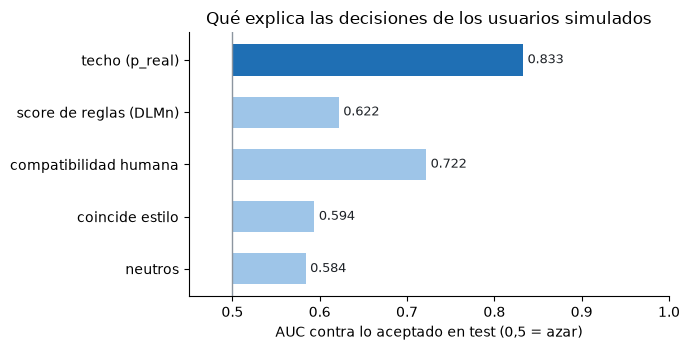

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
valores = auc["todos"].iloc[::-1]
ax.barh(valores.index, valores.values - 0.5, left=0.5, color=["#9ec5e8"] * (len(valores) - 1) + ["#1f6fb4"],
        height=0.6)
for y, v in enumerate(valores.values):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9, color="#1f2328")
ax.axvline(0.5, color="#8c959f", lw=1)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("AUC contra lo aceptado en test (0,5 = azar)")
ax.set_title("Qué explica las decisiones de los usuarios simulados")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
RES.mkdir(parents=True, exist_ok=True)
fig.savefig(RES / "fig_usuarios_senales.png", dpi=150)
plt.show()

## 5. Salidas

In [8]:
perfiles.to_csv(PROC / "usuarios.csv", index=False, encoding="utf-8")
closets.to_csv(PROC / "closets.csv", index=False, encoding="utf-8")
historial.to_csv(PROC / "historial.csv", index=False, encoding="utf-8")
usados = items[items["item_id"].isin(closets["item_id"])].drop(columns="particion")
usados.to_csv(PROC / "items_fase1.csv", index=False, encoding="utf-8")
for f in ["usuarios.csv", "closets.csv", "historial.csv", "items_fase1.csv"]:
    print(f, (PROC / f).stat().st_size // 1024, "KB")
print("Prendas distintas en clósets:", usados["origen"].value_counts().to_dict())

usuarios.csv 45 KB
closets.csv 650 KB
historial.csv 2885 KB
items_fase1.csv 1365 KB
Prendas distintas en clósets: {'polyvore': 9437, 'propio': 500}
